# Physics Informed Neural Nets

### Introduction

PDEs are widely used to model physical processes such as heat transfer, diffusion, fluid flow, and wave propagation, but many PDEs become difficult or impossible to solve analytically when the geometry, boundary conditions, or coefficients become complicated. PINNs are a relatively new computational approach that combines neural networks with known physical laws. Instead of training only on experimental data, a PINN is trained so that its predicted solution also satisfies the governing PDE and its initial and boundary conditions. It can be basically thought of as function estimation using neural networks. They can also simultaneously perform parameter estimation when a coefficient of a PDE is not known but there is experimental data that can be used to infer it. They are also meshless, meaning they can predict for all inputs within a continuous domain in contrast to numerical solvers that divide the domain into finite grids. Hence, they are important to consider as alternatives for regular numerical solvers.

### Problem Definition: One-Dimensional Heat Equation

We consider the one-dimensional heat equation describing the evolution of a temperature distribution along a homogeneous rod. The governing partial differential equation (PDE) is given by

$$
\frac{\partial u(x,t)}{\partial t}=\alpha\frac{\partial^2u(x,t)}{\partial x^2},
$$

where $u(x,t)$ represents the temperature at position $x$ and time $t$, and $\alpha$ is the thermal diffusivity coefficient, taken as $\alpha=0.01$.

The problem is defined over the space-time domain

$$
(x,t)\in\Omega=[0,1]\times[0,1].
$$

The initial temperature distribution is prescribed as a superposition of three sinusoidal functions:

$$
u(x,0)=\sin(2\pi x)+0.7\sin(5\pi x)+0.4\sin(9\pi x),
\quad x\in[0,1].
$$

Homogeneous Dirichlet boundary conditions are imposed at both ends of the rod:

$$
u(0,t)=0,\qquad u(1,t)=0,
\quad t\in[0,1].
$$

### PINN

The basic idea is to exploit universal approximation theorem and make the neural net approximate the solution function that obeys given PDE with specified boundary and initial conditions. To do so, we will construct a loss function that will penalize how far we are from satisfying PDE and given conditions. Our loss function will consist of the following components:
- $\mathcal L_{\mathrm{PDE}}=\frac{1}{N_f}\sum_{i=1}^{N_f}\left(
\frac{\partial u_\theta}{\partial t}(x_i,t_i)
-0.01\frac{\partial^2u_\theta}{\partial x^2}(x_i,t_i)
\right)^2$
- $\mathcal L_{\mathrm{IC}} = \frac{1}{N_0}\sum_{i=1}^{N_0}\left(u_{\theta}(x,0)-\sin(2\pi x)+0.7\sin(5\pi x)+0.4\sin(9\pi x)\right)^2$
- $\mathcal L_{\mathrm{BC}}= \frac{1}{N_b}\sum_{i=1}^{N_b}\left(u_{\theta}(0,t)^2+u_{\theta}(1,t)^2\right)$

Here $N_f$, $N_b$, and $N_0$ correspond to sampled points for that loss. Total (weighted) loss will be:

$$
\mathcal L_{\mathrm{total}}=
\lambda_f\mathcal L_{\mathrm{PDE}}+
\lambda_0\mathcal L_{\mathrm{IC}}+
\lambda_b\mathcal L_{\mathrm{BC}}
$$

In [12]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags_array
from scipy.sparse.linalg import factorized

# Fix random seed
seed = 42
torch.manual_seed(seed)
np.random.default_rng(seed)

# Hardware acceleration
device = torch.accelerator.current_accelerator(check_available=True)
if device is None:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: mps


### Dataset

We will create our own dataset to train our Neural PDE solver. We want a dense $(x,t)$ mesh to obtain a smooth solution. Same applies for BC and IC data. 

In [13]:
# 1000 x 1000 grid with total of a million points
n, dtype = 1000, torch.float32

# Coordinate vectors: shape [1000]
X = torch.linspace(0, 1, n, device=device, dtype=dtype)
T = torch.linspace(0, 1, n, device=device, dtype=dtype)

# All combinations of x and t
x_grid, t_grid = torch.meshgrid(X, T, indexing="ij")
# print(x_grid, '\n', t_grid)

# PDE coordinates: shape [1_000_000, 2], columns (x, t)
XT = torch.stack([x_grid.reshape(-1), t_grid.reshape(-1)],dim=1,)


# Initial condition: (x, 0), shape [1000, 2]
XT_0 = torch.stack([X, torch.zeros_like(X)], dim=1)


# Left boundary: (0, t), shape [1000, 2]
XT_L = torch.stack([torch.zeros_like(T), T], dim=1)


# Right boundary: (1, t), shape [1000, 2]
XT_R = torch.stack([1*torch.ones_like(T), T], dim=1)

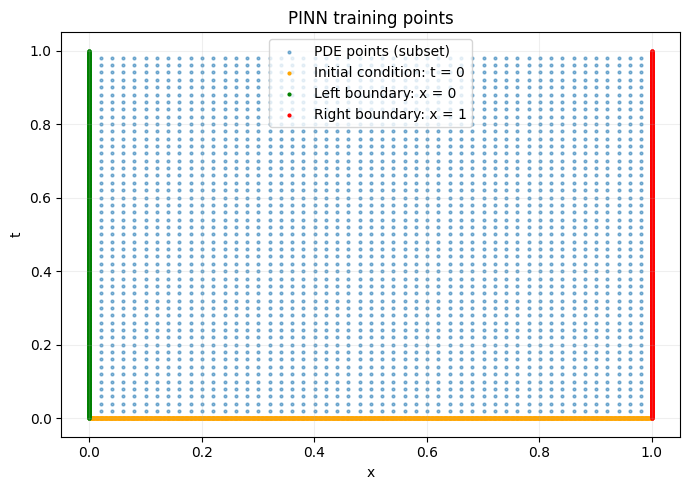

In [14]:
def to_numpy(tensor):
    return tensor.detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(7, 5))

# Show a subset of the million grid points for readability
ax.scatter(
    to_numpy(x_grid[::20, ::20]).ravel(),
    to_numpy(t_grid[::20, ::20]).ravel(),
    s=4,
    alpha=0.5,
    label="PDE points (subset)",
)

# Initial and boundary points
for points, label, color in [
    (XT_0, "Initial condition: t = 0", "orange"),
    (XT_L, "Left boundary: x = 0", "green"),
    (XT_R, "Right boundary: x = 1", "red"),
]:
    points = to_numpy(points)
    ax.scatter(
        points[:, 0],  # x coordinates
        points[:, 1],  # t coordinates
        s=4,
        color=color,
        label=label,
    )

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_title("PINN training points")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Model

Our model will be a standard MLP. The only adjustment will be to use `tanh` instead of `ReLU` for non-linear activations to prevent vanishing second derivatives.

In [15]:
class NeuralPDE(nn.Module):
    def __init__(self, hidden_dim=64, num_hidden_layers=4):
        super().__init__()

        # We will use Tanh because its second derivative does not vanish
        layers = [nn.Linear(2, hidden_dim), nn.Tanh()]
        for _ in range(num_hidden_layers - 1):
            layers.extend([
                nn.Linear(hidden_dim, hidden_dim),
                nn.Tanh(),
            ])
        layers.append(nn.Linear(hidden_dim, 1))

        self.model = nn.Sequential(*layers)

    def forward(self, z):
        # z: [batch_size, 2], e.g. coordinates (x, t)
        # u: [batch_size, 1], predicted PDE solution
        return self.model(z)

### Loss Function

Below we use the `autograd` functionality of PyTorch to calculate the PDE losses. The BC and IC losses are trivial and do not require any differentiation.

In [16]:
def gradient(y, inputs):
    return torch.autograd.grad(
        outputs=y,
        inputs=inputs,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
    )[0]


def pinn_loss(
    model,
    xt_f,                 # [N_f, 2]: interior coordinates (x, t)
    xt_0,                 # [N_0, 1]: initial condition (x, 0)
    xt_left,              # [N_b, 1]: boundary condition (0, t)
    xt_right,             # [N_b, 1]: boundary condition (1, t)
    lambda_f=1.0,
    lambda_0=1.0,
    lambda_b=1.0,
):
    # PDE loss
    xt_f = xt_f.detach().requires_grad_(True)
    u = model(xt_f)          # [N_f, 1]
    
    du = gradient(u, xt_f)   # [N_f, 2]
    u_x = du[:, 0:1]         # [N_f, 1]
    u_t = du[:, 1:2]
    u_xx = gradient(u_x, xt_f)[:, 0:1]

    residual = u_t - 0.01 * u_xx
    loss_pde = residual.square().mean()


    # Initial condition loss: t = 0
    u_0 = model(xt_0)
    
    x_0 = xt_0[:, 0:1]   # [N_0, 1]
    target_0 = (
        torch.sin(2 * torch.pi * x_0)
        - 0.7 * torch.sin(5 * torch.pi * x_0)
        - 0.4 * torch.sin(9 * torch.pi * x_0)
    )

    loss_ic = (u_0 - target_0).square().mean()


    # Boundary condition loss: x = 0 and x = 1
    u_left = model(xt_left)
    u_right = model(xt_right)
    
    loss_bc = (u_left.square() + u_right.square()).mean()


    # Total weighted loss
    total = (
        lambda_f * loss_pde
        + lambda_0 * loss_ic
        + lambda_b * loss_bc
    )
    
    return total, {
        "pde": loss_pde,
        "ic": loss_ic,
        "bc": loss_bc,
    }

### Training

We will now train our model on our synthetic dataset. In contrast to most of the deep learning training, our goal is to **overfit** because to enforce physics constraint, **loss function**, as good as possible.

In [17]:
# Training parameters
points_per_epoch = 10_000
num_epochs = 200
batch_size = 128

# Batch sampling helper
def sample_batch(data, batch_size):
    indices = torch.randint(
            len(data),
            size=(batch_size,),
            device=data.device,
        )
    return data[indices]

# Model and optimizer
model = NeuralPDE().to(device=device, dtype=dtype)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Initialize training
history = []
model.train()

print("Starting training...")
for epoch in range(num_epochs):
    epoch_sums = {"total": 0.0, "pde": 0.0, "ic": 0.0, "bc": 0.0}
    num_points = 0

    # For faster training sample random subset per epoch
    train_data = DataLoader(
            TensorDataset(sample_batch(XT, points_per_epoch)),
            batch_size=batch_size,
            shuffle=True,
        )

    # Push randomly sampled BC & IC data of batch size
    xt_0 = sample_batch(XT_0, batch_size)
    xt_l = sample_batch(XT_L, batch_size)
    xt_r = sample_batch(XT_R, batch_size)

    for batch in train_data:
        xt = batch[0]
        optimizer.zero_grad(set_to_none=True)

        loss, terms = pinn_loss(model, xt, xt_0, xt_l, xt_r)
        loss.backward()
        optimizer.step()

        # Weight batch averages by batch size
        n = xt.shape[0]
        num_points += n

        for name, value in terms.items():
            epoch_sums[name] += value.detach().item() * n
            epoch_sums["total"] += value.detach().item() * n

    epoch_means = {
        name: value / num_points
        for name, value in epoch_sums.items()
    }
    history.append(epoch_means)

    if (epoch + 1) % 10 == 0:
        metrics = ", ".join(
            f"{name}={value:.6f}"
            for name, value in epoch_means.items()
        )
        print(f"Epoch {epoch + 1}: {metrics}")

Starting training...
Epoch 10: total=0.092981, pde=0.008615, ic=0.072287, bc=0.012080
Epoch 20: total=0.064063, pde=0.005170, ic=0.052363, bc=0.006530
Epoch 30: total=0.052744, pde=0.007370, ic=0.037906, bc=0.007467
Epoch 40: total=0.035732, pde=0.007570, ic=0.023327, bc=0.004834
Epoch 50: total=0.025193, pde=0.006123, ic=0.014816, bc=0.004254
Epoch 60: total=0.017112, pde=0.005793, ic=0.008718, bc=0.002601
Epoch 70: total=0.012100, pde=0.004277, ic=0.005907, bc=0.001915
Epoch 80: total=0.008244, pde=0.003384, ic=0.003673, bc=0.001186
Epoch 90: total=0.005474, pde=0.002176, ic=0.002350, bc=0.000948
Epoch 100: total=0.004247, pde=0.002115, ic=0.001541, bc=0.000592
Epoch 110: total=0.006006, pde=0.003037, ic=0.001700, bc=0.001269
Epoch 120: total=0.002639, pde=0.001290, ic=0.000810, bc=0.000539
Epoch 130: total=0.002282, pde=0.001305, ic=0.000634, bc=0.000343
Epoch 140: total=0.001776, pde=0.001000, ic=0.000431, bc=0.000345
Epoch 150: total=0.001726, pde=0.000909, ic=0.000402, bc=0.00041

### PINN Results

Plot the results at individual time snapshots

In [18]:
def plot_heat(*solutions, plot_snapshots=True, plot_heatmap=False):
    """Accept one or more (x, t, U, title, label) tuples,
    it assumes same time arrays when plotting multiple at once."""
    if plot_snapshots:
        t = solutions[0][1]
        indices = np.linspace(0, len(t) - 1, 12, dtype=int)

        fig, axes = plt.subplots(
            4, 3, figsize=(14, 14), sharex=True, sharey=True,
            constrained_layout=True,
        )

        for ax, k in zip(axes.flat, indices):
            styles = ["-", "--", ":", "-."]
            markers = [None, "o", "s", "^"]
            for j, (x, _, U, title, label) in enumerate(solutions):
                ax.plot(
                    x, U[k],
                    label=label,
                    linestyle=styles[j % len(styles)],
                    marker=markers[j % len(markers)],
                    markevery=max(1, len(x) // 12),
                    markersize=4,
                    markerfacecolor="none",
                    linewidth=1.5,
                )

            ax.set_title(f"t = {t[k]:.4g}")
            ax.set_xlabel("x")
            ax.set_ylabel("u(x, t)")
            ax.grid(alpha=0.3)
            ax.legend()

        fig.suptitle(" / ".join(s[3] for s in solutions))
        plt.show()

    if plot_heatmap:
        fig, axes = plt.subplots(
            1, len(solutions),
            figsize=(3 * len(solutions), 2),
            squeeze=False,
            constrained_layout=True,
        )

        for ax, (x, t, U, title, label) in zip(axes.flat, solutions):
            heatmap = ax.imshow(
                U, origin="lower", aspect="auto",
                interpolation="nearest",
                extent=[x[0], x[-1], t[0], t[-1]],
                cmap="RdBu_r", vmin=-1, vmax=1,
            )
            ax.set_xlabel("x")
            ax.set_ylabel("t")
            ax.set_title(title)
            fig.colorbar(heatmap, ax=ax, label="u(x, t)")

        plt.show()

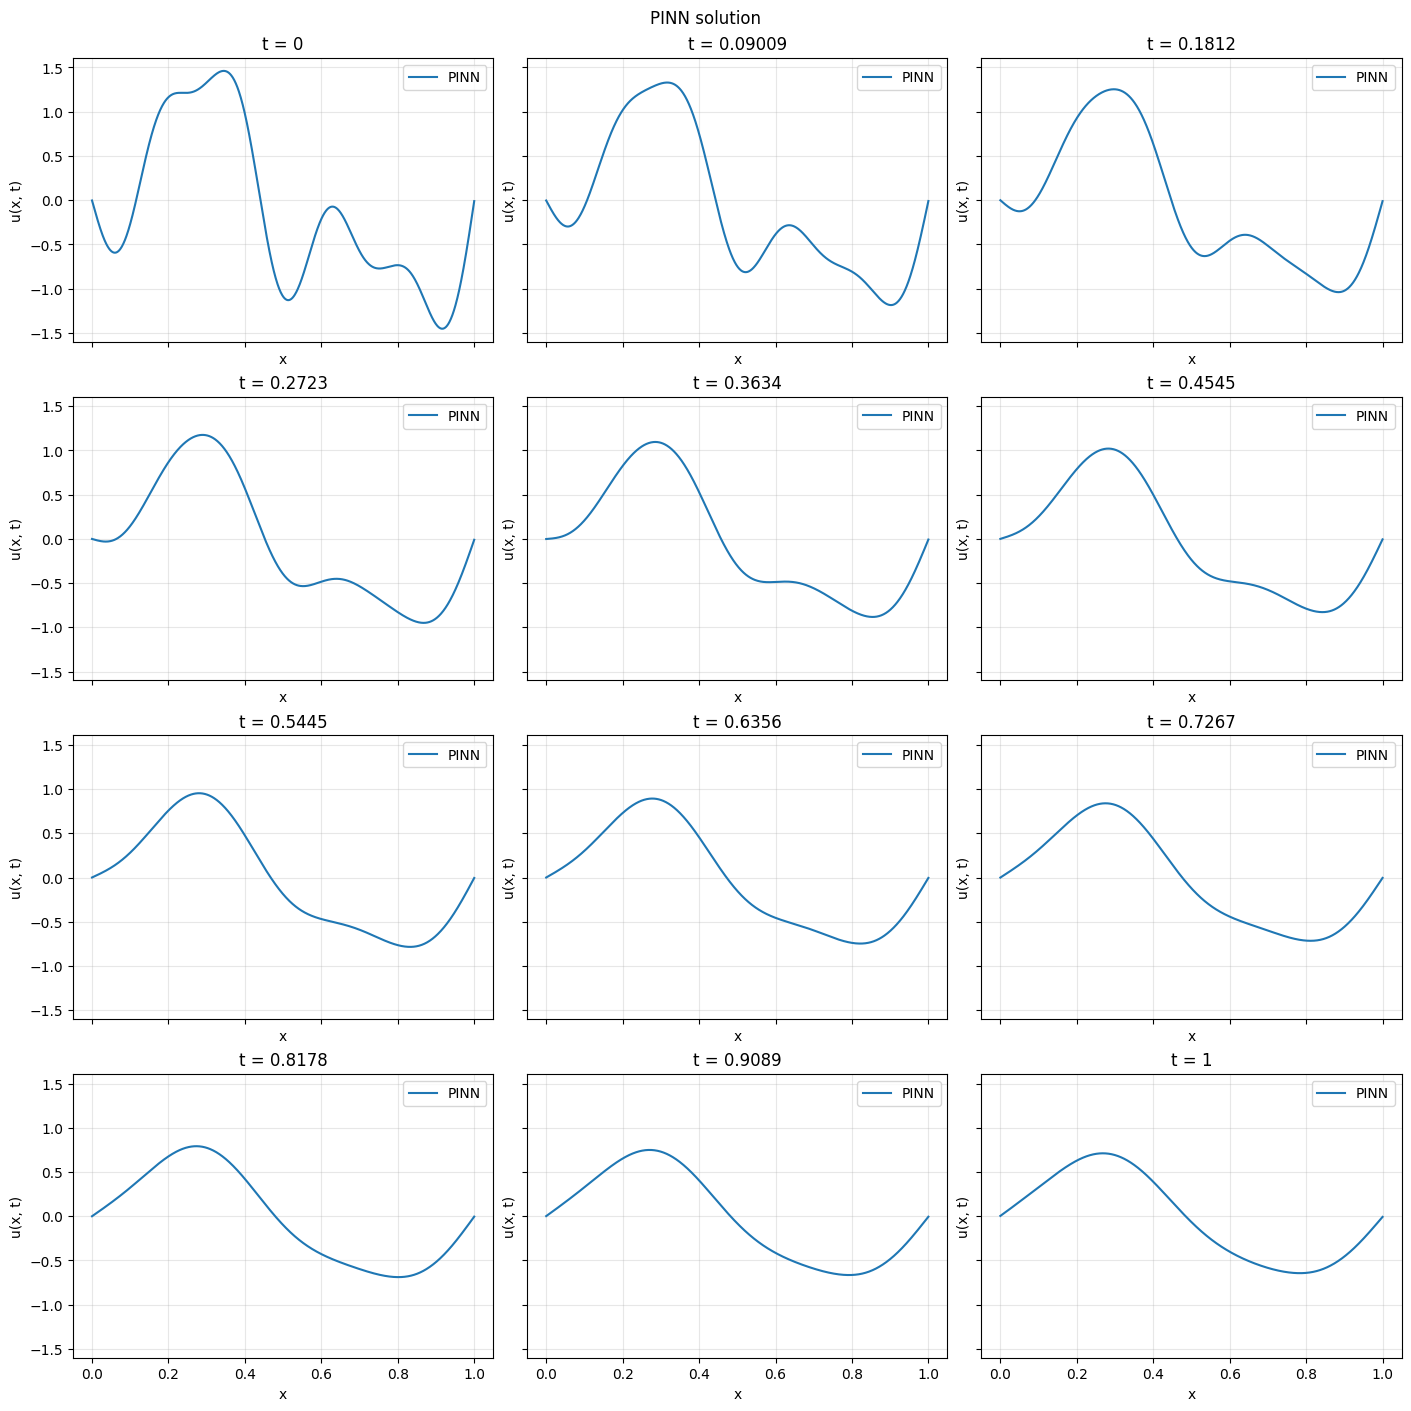

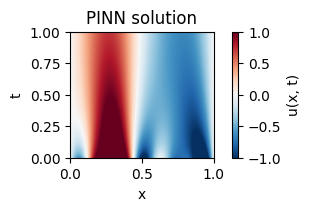

In [19]:
def pinn_solve(model, x, t):
    # To retrieve the device and data type
    parameter = next(model.parameters())
    x = torch.as_tensor(x, device=parameter.device, dtype=parameter.dtype)
    t = torch.as_tensor(t, device=parameter.device, dtype=parameter.dtype)

    model.eval()
    snapshots = []
    with torch.no_grad():
        for time in t:
            time_snapshot = torch.stack(
                [x, time.expand_as(x)],
                dim=1,
            )
            u = model(time_snapshot).squeeze(-1)
            snapshots.append(u)

    # Shape: [len(t), len(x)]
    return torch.stack(snapshots).cpu().numpy()


pinn_x = to_numpy(X)
pinn_t = to_numpy(T)
pinn_U = pinn_solve(model, pinn_x, pinn_t)
plot_heat(
    (pinn_x, pinn_t, pinn_U, "PINN solution", "PINN"),
    plot_heatmap=True,
)

### Numerical Solution

We will also use numerical solver to compare with out PINN solution.

In [20]:
def solve_heat(dx, method="explicit", steps=8000, dt=None, l=1,
               alpha=lambda t: 0.0, beta=lambda t: 0.0, c=1.0):
    """Solve u_t = c u_xx with zero initial data; return x, times, U."""
    if method not in ("explicit", "implicit"):
        raise ValueError("method must be 'explicit' or 'implicit'")

    if dt is None:
        # Stability condition for explicit method
        dt = dx**2 / (4 * c)
    n = int(round(l / dx)) - 1
    mu = c * dt / dx**2

    # Initial condition (internal points, boundaries will be appended seperately)
    x_0 = np.linspace(0,l,n+2)[1:-1]
    u_0 = (
            np.sin(2 * np.pi * x_0)
            - 0.7 * np.sin(5 * np.pi * x_0)
            - 0.4 * np.sin(9 * np.pi * x_0)
        )

    # b vector
    b = lambda t: mu * np.concatenate(
        ([alpha(t)], np.zeros(n - 2), [beta(t)])
    )

    # A matrix
    if method == "explicit":
        A = diags_array(
            [np.full(n - 1, mu), np.full(n, 1 - 2*mu), np.full(n - 1, mu)],
            offsets=[-1, 0, 1], shape=(n, n), format="csr",
        )
    else:
        A = diags_array(
            [np.full(n - 1, -mu), np.full(n, 1 + 2*mu), np.full(n - 1, -mu)],
            offsets=[-1, 0, 1], shape=(n, n), format="csc",
        )
        solve = factorized(A)

    # Initialize u and results list
    results = [u_0.copy()]
    u = u_0.copy()
    for i in range(steps):
        if method == "explicit":
            u = A @ u + b(i * dt)
        else:
            u = solve(u + b((i + 1) * dt))
        results.append(u)

    # Complete x, t, and U
    x = np.linspace(0, l, n + 2)
    times = np.arange(steps + 1) * dt
    U = np.column_stack([
        [alpha(t) for t in times],
        np.asarray(results),
        [beta(t) for t in times],
    ])
    return x, times, U, dt

### Exact Analytical Solution

The exact solution is given by

$$
\begin{aligned}
u(x,t)={}&e^{-0.04\pi^2t}\sin(2\pi x)\\
&-0.7e^{-0.25\pi^2t}\sin(5\pi x)\\
&-0.4e^{-0.81\pi^2t}\sin(9\pi x).
\end{aligned}
$$

This analytical solution serves as a reference for evaluating the accuracy of the Physics-Informed Neural Network (PINN) and the numerical finite difference approximation.

In [21]:
def exact_solve(x, t):
    x = np.asarray(x)[None, :]  # [1, num_x]
    t = np.asarray(t)[:, None]  # [num_t, 1]

    # Shape: [len(t), len(x)]
    return (
        np.exp(-0.04 * np.pi**2 * t) * np.sin(2 * np.pi * x)
        - 0.7 * np.exp(-0.25 * np.pi**2 * t) * np.sin(5 * np.pi * x)
        - 0.4 * np.exp(-0.81 * np.pi**2 * t) * np.sin(9 * np.pi * x)
    )

### Comparison of all solutions

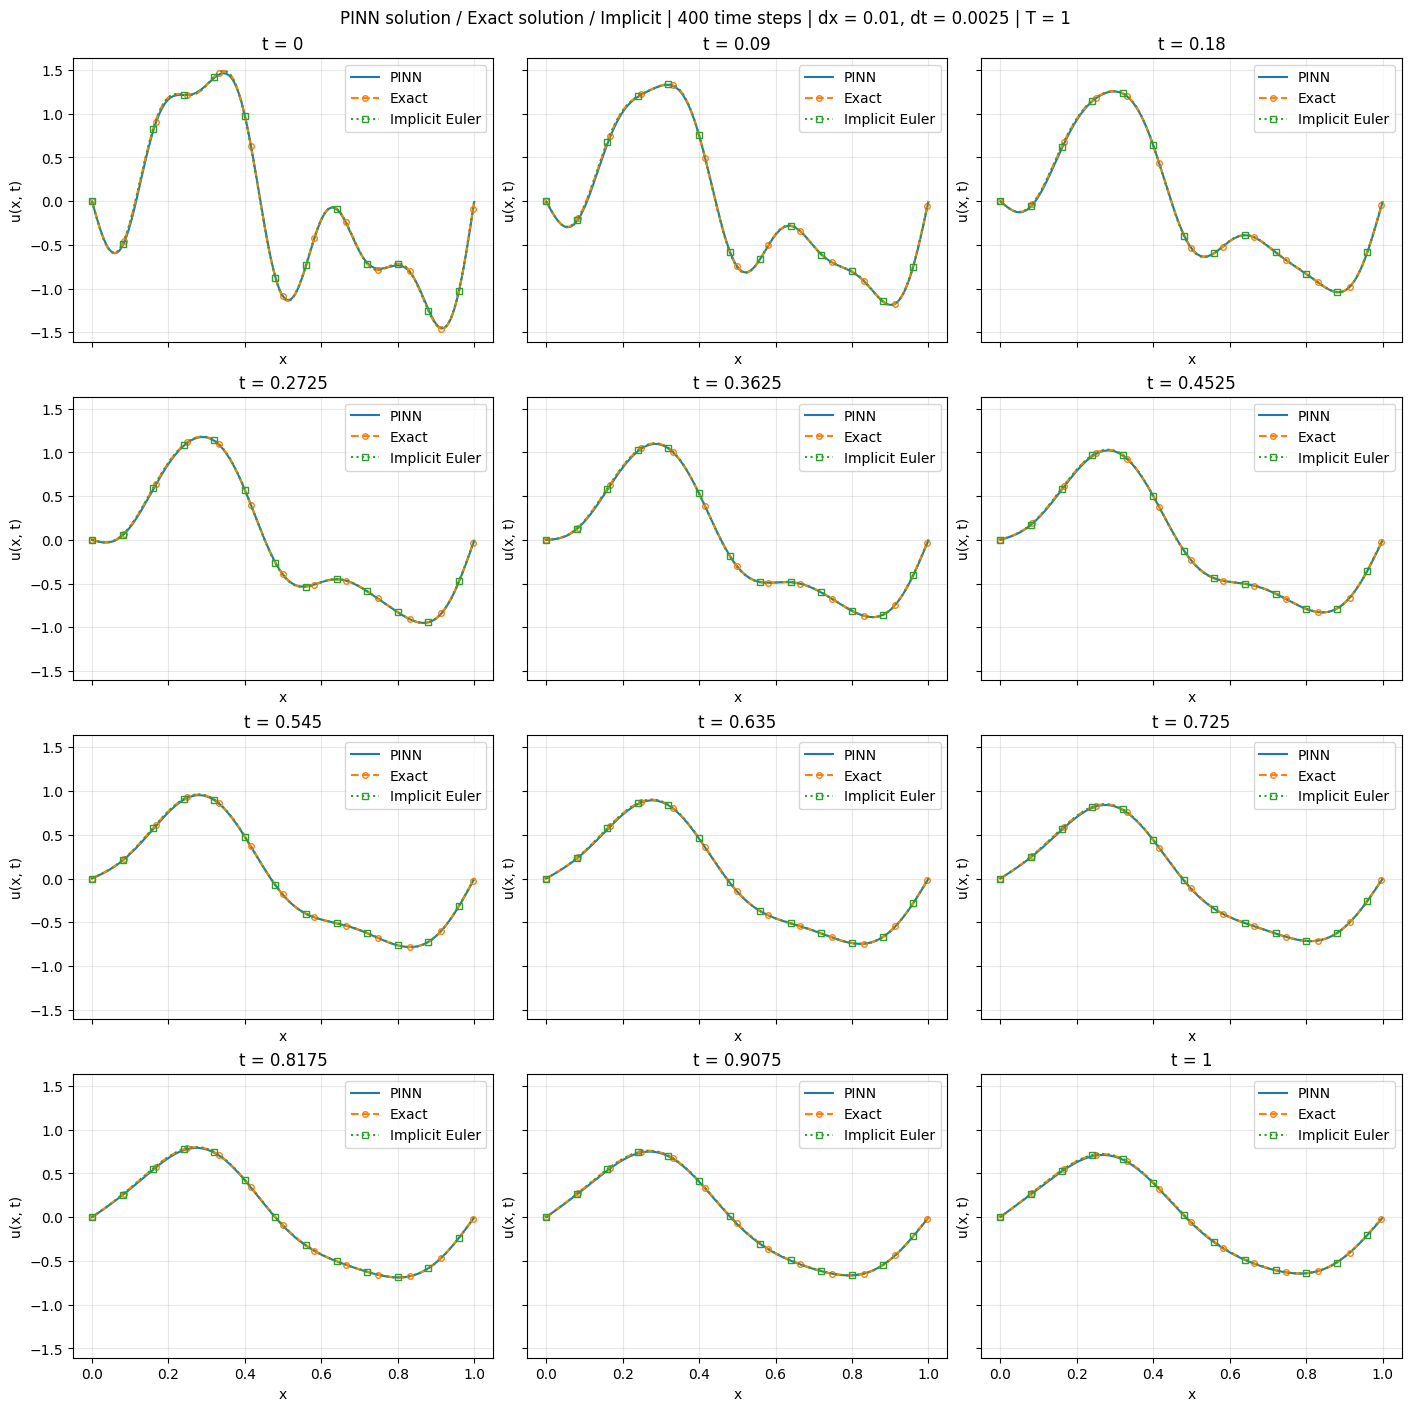

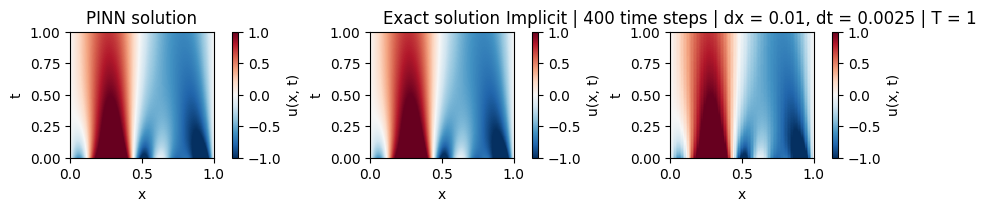

In [22]:
# Explicit (forward) Euler numerical solution
fwd_method = "explicit"
fwd_steps = 400
fwd_dx = 0.01
fwd_x, fwd_t, fwd_U, fwd_dt = solve_heat(fwd_dx, fwd_method, fwd_steps, dt=None, l=1, alpha=lambda t: 0.0, beta=lambda t: 0.0, c=0.01)

fwd_label = "Explicit" if fwd_method == "explicit" else "Implicit"
fwd_title = f"{fwd_label} | {fwd_steps} time steps | dx = {fwd_dx:.4g}, dt = {fwd_dt:.4g} | T = {fwd_t[-1]:.4g}"


# Implicit (backward) Euler numerical solution
bwd_method = "implicit"
bwd_steps = 400
bwd_dx = 0.01
bwd_x, bwd_t, bwd_U, bwd_dt = solve_heat(bwd_dx, bwd_method, bwd_steps, dt=None, l=1, alpha=lambda t: 0.0, beta=lambda t: 0.0, c=0.01)

bwd_label = "Explicit" if bwd_method == "explicit" else "Implicit"
bwd_title = f"{bwd_label} | {bwd_steps} time steps | dx = {bwd_dx:.4g}, dt = {bwd_dt:.4g} | T = {bwd_t[-1]:.4g}"


# Exact solution
exact_x = to_numpy(X)
exact_t = fwd_t   # Everything evaluated at same times
exact_U = exact_solve(exact_x, exact_t)


# PINN solution
pinn_x = to_numpy(X)
pinn_t = fwd_t
pinn_U = pinn_solve(model, pinn_x, pinn_t)


# Plot all
plot_heat(
    (pinn_x, pinn_t, pinn_U, "PINN solution", "PINN"),
    (exact_x, exact_t, exact_U, "Exact solution", "Exact"),
    # (fwd_x, fwd_t, fwd_U, fwd_title, f"{fwd_label} Euler"),
    (bwd_x, bwd_t, bwd_U, bwd_title, f"{bwd_label} Euler"),
    plot_heatmap=True
)

### References

- Raissi M, Perdikaris P, Karniadakis GE (2019). Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. Journal of Computational Physics 378:686-707.
- Lagaris IE, Likas A, Fotiadis DI (1998). Artificial neural networks for solving ordinary and partial differential equations. IEEE Transactions on Neural Networks 9(5):987-1000.
- Karniadakis GE, Kevrekidis IG, Lu L, Perdikaris P, Wang S, Yang L (2021). Physics-informed machine learning. Nature Reviews Physics 3:422-440.
